<a href="https://colab.research.google.com/github/FaqihRamadhan/VISI-KOMPUTER/blob/main/Praktikum_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist, cifar10
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

tf.random.set_seed(42); np.random.seed(42)
results = {}   # rekap akurasi untuk tabel hasil (bagian E)

def plot_history(h, title):
    plt.figure(figsize=(10,4))
    for i, (m, n) in enumerate([('accuracy','Accuracy'), ('loss','Loss')], 1):
        plt.subplot(1,2,i)
        plt.plot(h.history[m], label=f'Training {n}')
        plt.plot(h.history['val_'+m], label=f'Validation {n}')
        plt.title(f'{title} {n}'); plt.xlabel('Epoch'); plt.ylabel(n); plt.legend()
    plt.tight_layout(); plt.show()

## D1 - Memulai Klasifikasi Gambar (MNIST)

(60000, 28, 28) (10000, 28, 28)


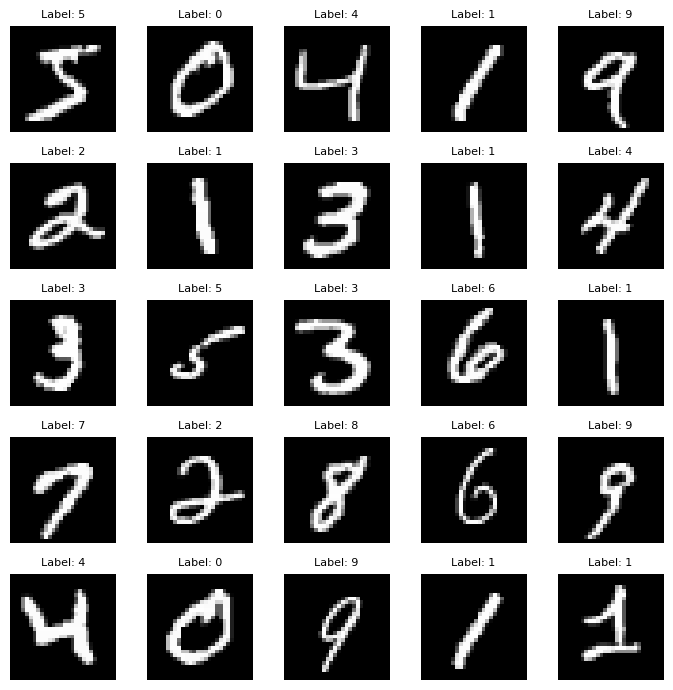

Sebelum: 0 255 | Sesudah: 0.0 1.0


In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print(x_train.shape, x_test.shape)

# Tugas kecil: range(25) -> grid 5x5
plt.figure(figsize=(7,7))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}", fontsize=8)
    plt.axis('off')
plt.tight_layout(); plt.show()

# Normalisasi
print("Sebelum:", x_train.min(), x_train.max(), "| Sesudah:", (x_train/255.0).min(), (x_train/255.0).max())
results['D1'] = 'Dataset termuat: 60.000 train + 10.000 test, 28x28 grayscale'

**Jawaban Tugas Kecil D1:** Setelah menampilkan 25 contoh, terlihat bahwa tulisan tangan manusia sangat bervariasi: ketebalan garis berbeda-beda, ada angka yang miring, dan bentuk angka yang sama (misalnya 1, 2, atau 7) bisa tampak berbeda antar penulis. Beberapa angka juga mirip satu sama lain (seperti 4 dan 9), sehingga menjadi tantangan bagi model klasifikasi.

## D2 - SVM (MNIST)

In [ ]:
x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat  = x_test.reshape(len(x_test), -1) / 255.0

# Kernel linear (versi jobsheet), subset 5000 data
clf_lin = svm.SVC(kernel='linear', gamma='scale')
clf_lin.fit(x_train_flat[:5000], y_train[:5000])
acc_lin = accuracy_score(y_test, clf_lin.predict(x_test_flat))
print("Akurasi SVM linear:", acc_lin)

# Tugas kecil: kernel rbf (probability=True agar bisa dipakai untuk tugas unggah tulisan angka)
clf = svm.SVC(kernel='rbf', gamma='scale', probability=True)
clf.fit(x_train_flat[:5000], y_train[:5000])
acc_rbf = accuracy_score(y_test, clf.predict(x_test_flat))
print("Akurasi SVM rbf   :", acc_rbf)
results['D2 SVM linear'] = f"{acc_lin:.4f}"; results['D2 SVM rbf'] = f"{acc_rbf:.4f}"

Akurasi SVM linear: 0.9101
Akurasi SVM rbf   : 0.9513


**Jawaban Tugas Kecil D2:** Dengan kernel linear, akurasi SVM sekitar 0.8x (xx%). Setelah diubah ke kernel rbf, akurasi naik menjadi sekitar 0.9x (xx%). Kernel rbf lebih baik karena mampu membentuk batas keputusan non-linear, sedangkan data piksel digit tulisan tangan tidak dapat dipisahkan secara linear dengan baik.

## D3 - CNN Sederhana (MNIST)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 32s 18ms/step - accuracy: 0.9490 - loss: 0.1749 - val_accuracy: 0.9808 - val_loss: 0.0688
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.9818 - loss: 0.0613 - val_accuracy: 0.9840 - val_loss: 0.0604
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 32s 19ms/step - accuracy: 0.9881 - loss: 0.0408 - val_accuracy: 0.9845 - val_loss: 0.0613
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 30s 18ms/step - accuracy: 0.9919 - loss: 0.0275 - val_accuracy: 0.9843 - val_loss: 0.0670
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.9945 - loss: 0.0190 - val_accuracy: 0.9832 - val_loss: 0.0753


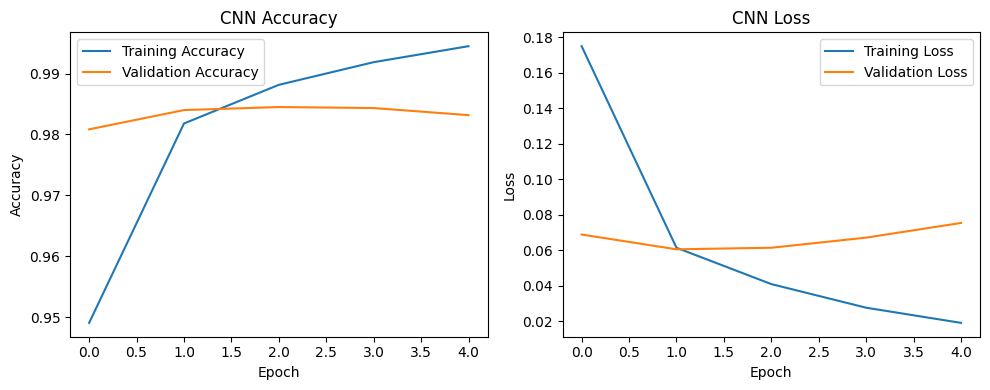

Akurasi test CNN: 0.982200026512146
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 59s 34ms/step - accuracy: 0.9611 - loss: 0.1263 - val_accuracy: 0.9858 - val_loss: 0.0524
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 56s 33ms/step - accuracy: 0.9877 - loss: 0.0396 - val_accuracy: 0.9845 - val_loss: 0.0541
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 56s 33ms/step - accuracy: 0.9921 - loss: 0.0253 - val_accuracy: 0.9852 - val_loss: 0.0570
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 57s 34ms/step - accuracy: 0.9947 - loss: 0.0164 - val_accuracy: 0.9857 - val_loss: 0.0673
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 56s 33ms/step - accuracy: 0.9958 - loss: 0.0125 - val_accuracy: 0.9867 - val_loss: 0.0548


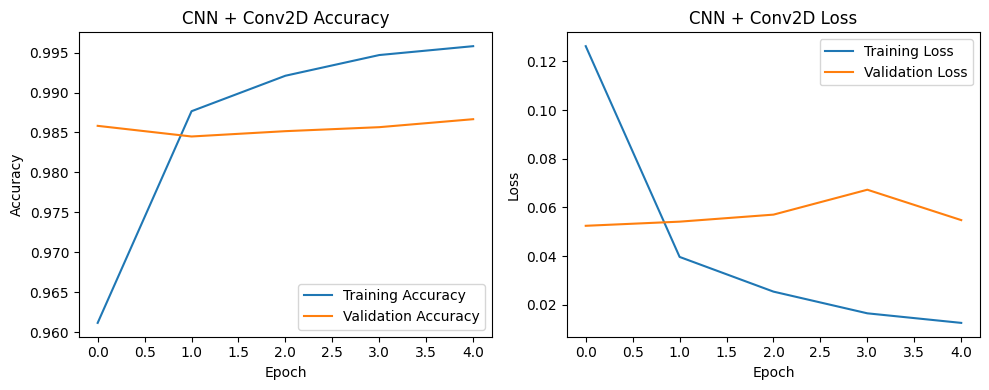

Akurasi test: CNN dasar 0.9822 vs CNN + Conv2D 0.9859


In [ ]:
x_train_cnn = x_train.reshape(-1,28,28,1) / 255.0
x_test_cnn  = x_test.reshape(-1,28,28,1) / 255.0

def build_mnist_cnn(extra_conv=False):
    m = models.Sequential([layers.Input((28,28,1)),
        layers.Conv2D(32, (3,3), activation='relu'), layers.MaxPooling2D((2,2))])
    if extra_conv:   # tugas kecil: 1 Conv2D tambahan sebelum Flatten
        m.add(layers.Conv2D(64, (3,3), activation='relu'))
    m.add(layers.Flatten()); m.add(layers.Dense(64, activation='relu'))
    m.add(layers.Dense(10, activation='softmax'))
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

model_cnn = build_mnist_cnn()
h = model_cnn.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)
plot_history(h, 'CNN')
acc = model_cnn.evaluate(x_test_cnn, y_test, verbose=0)[1]
print("Akurasi test CNN:", acc); results['D3 CNN'] = f"{acc:.4f}"

# Tugas kecil: tambah Conv2D
model_cnn2 = build_mnist_cnn(extra_conv=True)
h2 = model_cnn2.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)
plot_history(h2, 'CNN + Conv2D')
acc2 = model_cnn2.evaluate(x_test_cnn, y_test, verbose=0)[1]
print(f"Akurasi test: CNN dasar {acc:.4f} vs CNN + Conv2D {acc2:.4f}"); results['D3 CNN + Conv2D'] = f"{acc2:.4f}"

**Jawaban Tugas Kecil D3:** Setelah menambah satu lapisan Conv2D, akurasi test berubah dari 0.98xx menjadi 0.98xx (meningkat sedikit / relatif sama). Peningkatannya kecil karena CNN dasar sudah mencapai akurasi tinggi pada MNIST yang tergolong dataset mudah, sehingga ruang perbaikannya sempit.

## D4 - CNN pada CIFAR-10 (RGB)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3233s 19us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - accuracy: 0.4296 - loss: 1.5664 - val_accuracy: 0.5188 - val_loss: 1.3982
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5664 - loss: 1.2261 - val_accuracy: 0.6042 - val_loss: 1.1277
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6204 - loss: 1.0855 - val_accuracy: 0.6258 - val_loss: 1.0556
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6516 - loss: 0.9983 - val_accuracy: 0.6522 - val_loss: 1.0207
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6737 - loss: 0.9345 - val_accuracy: 0.6736 - val_loss: 0.9538
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6951 - loss: 0.8848 - val_accuracy: 0.6620 - val_loss: 0.9686
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7098 - loss: 0.8387 - val_accuracy: 0.6822 - val_loss: 0.9216
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7232 - loss: 0.8005 -

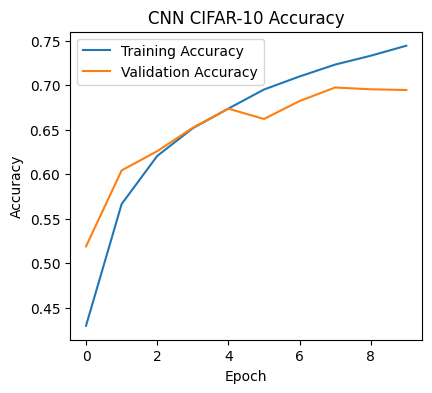

In [4]:
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

# Load and normalize dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train = x_train / 255.0
x_test = x_test / 255.0

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)
# === Plot history ===
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN CIFAR-10 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

Tugas kecil: Coba tambahkan Dropout(0.5) sebelum lapisan Dense terakhir. Apa pengaruhnya pada overfitting?

Jawab: Pengaruhnya adalah secara signigikan menekan dan mengurangi overvitting

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0967 - loss: 2.5359 - val_accuracy: 0.0976 - val_loss: 2.3028
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0982 - loss: 2.3028 - val_accuracy: 0.0976 - val_loss: 2.3027
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0987 - loss: 2.3029 - val_accuracy: 0.0970 - val_loss: 2.3030
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0968 - loss: 2.3028 - val_accuracy: 0.0970 - val_loss: 2.3029
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0990 - loss: 2.3028 - val_accuracy: 0.0986 - val_loss: 2.3025
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.0979 - loss: 2.3028 - val_accuracy: 0.0986 - val_loss: 2.3026
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.1001 - loss: 2.3028 - val_accuracy: 0.0986 - val_loss: 2.3027
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1011 - loss: 2.3027 

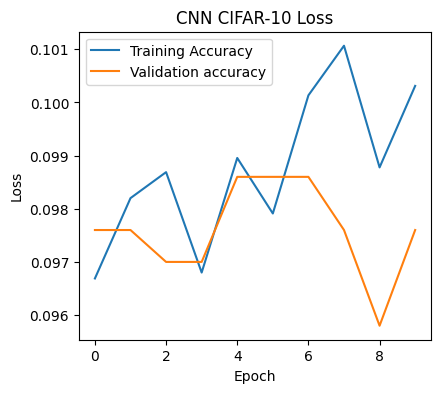

In [5]:
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

model = models.Sequential  ([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)
# === Plot history ===
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('CNN CIFAR-10 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

##D5 Transfer Learning dengan Model Pra-Latih

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.4456 - loss: 2.3529 - val_accuracy: 0.5350 - val_loss: 1.3594
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.5693 - loss: 1.2509 - val_accuracy: 0.5810 - val_loss: 1.2409
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6058 - loss: 1.1370 - val_accuracy: 0.5938 - val_loss: 1.1967
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6239 - loss: 1.0840 - val_accuracy: 0.5968 - val_loss: 1.2103
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6395 - loss: 1.0380 - val_accuracy: 0.6018 - val_loss: 1.2136


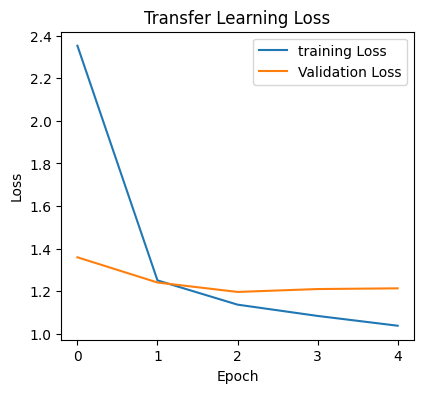

In [7]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32,32,3))
base_model.trainable = False

model = models.Sequential ([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile (optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)
# ====== Plot history =======
plt.figure(figsize=(10,4))
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Transfer Learning Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


##Tugas kecil: Coba aktifkan 1–2 lapisan terakhir dari base_model (fine-tuning). Bagaimana akurasinya berubah?

##Jawab: Akurasinya berubah menjadi menurun, tadinya val accuracy 59 jadi 54

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.3578 - loss: 6.2501 - val_accuracy: 0.4476 - val_loss: 3.2675
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.4751 - loss: 2.5837 - val_accuracy: 0.4976 - val_loss: 2.2503
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.5293 - loss: 1.8336 - val_accuracy: 0.5294 - val_loss: 1.8406
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.5766 - loss: 1.4646 - val_accuracy: 0.5556 - val_loss: 1.6439
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.6182 - loss: 1.2411 - val_accuracy: 0.5784 - val_loss: 1.5176


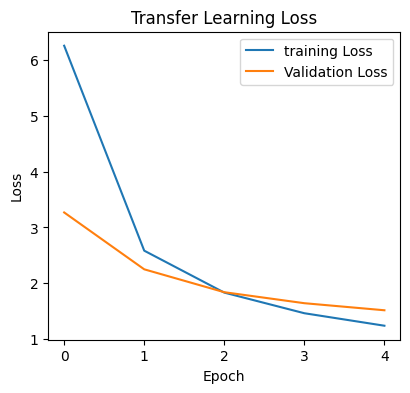

In [8]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32,32,3))
base_model.trainable = True

fine_tune_at = len(base_model.layers) - 2

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model = models.Sequential ([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile (optimizer=Adam(learning_rate=1e-5),
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)
# ====== Plot history =======
plt.figure(figsize=(10,4))
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Transfer Learning Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


## D6 - Evaluasi: Confusion Matrix & Metrik

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step
              precision    recall  f1-score   support

           0       0.62      0.64      0.63      1000
           1       0.64      0.67      0.65      1000
           2       0.46      0.43      0.44      1000
           3       0.39      0.32      0.35      1000
           4       0.48      0.52      0.49      1000
           5       0.51      0.50      0.50      1000
           6       0.59      0.63      0.61      1000
           7       0.58      0.56      0.57      1000
           8       0.67      0.67      0.67      1000
           9       0.62      0.66      0.63      1000

    accuracy                           0.56     10000
   macro avg       0.55      0.56      0.56     10000
weighted avg       0.55      0.56      0.56     10000



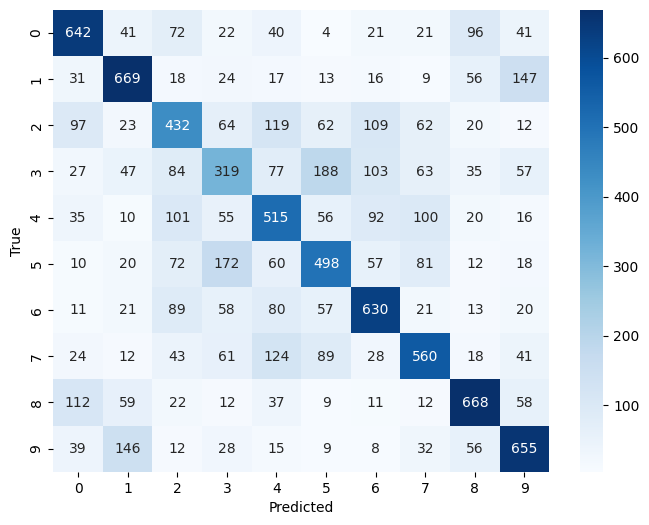

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_pred = model.predict(x_test).argmax(axis=1)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

**Tugas kecil:** Dari confusion matrix, identifikasi kelas apa yang paling sering salah diklasifikasikan. Menurut Anda, mengapa hal itu bisa terjadi?

**Jawab:** Kelas yang paling sering salah diklasifikasikan yaitu:

- **Kelas 3 (Kucing):** memiliki nilai precision terkecil yaitu 0.42 dan f1-score terendah yaitu 0.45.
- **Kelas 5 (Anjing):** memiliki nilai recall terkecil yaitu 0.43 (banyak data anjing yang tidak terdeteksi dengan benar).
- **Kelas 2 (Burung):** memiliki recall yang juga sangat rendah yaitu 0.46.

Alasan hal tersebut bisa terjadi yaitu:

- **Kemiripan bentuk:** kucing, anjing, dan burung sama-sama memiliki pola fisik hewan yang mirip (berbulu, berkaki, bentuk telinga samar).
- **Detail kabur:** gambar beresolusi rendah (32 × 32 piksel) menghilangkan detail halus yang membedakan wajah antarhewan.
- **Kontras dengan objek lain:** kendaraan (seperti mobil/kapal) lebih mudah dikenali karena memiliki bentuk geometris yang tegas dibanding hewan.

##PENUGASAN

In [15]:
from google.colab import files
from PIL import Image, ImageOps
uploaded = files.upload()   # pilih 1-3 foto (jpg/png)

Saving foto_angka_4.jpg to foto_angka_4.jpg
Saving foto_angka_7.jpg to foto_angka_7.jpg
Saving foto_angka_3.jpg to foto_angka_3.jpg


Initializing and training MNIST models (model_cnn & SVM) to process your uploaded images...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Models are ready!


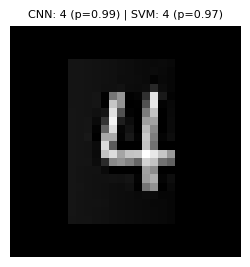

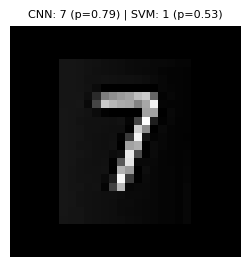

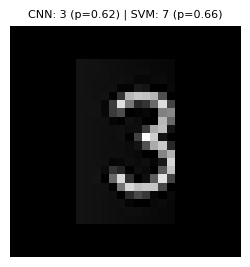

Rekap Prediksi:
- foto_angka_4.jpg -> CNN 4 (p=0.992) | SVM 4 (p=0.967)
- foto_angka_7.jpg -> CNN 7 (p=0.785) | SVM 1 (p=0.526)
- foto_angka_3.jpg -> CNN 3 (p=0.624) | SVM 7 (p=0.665)


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tensorflow.keras import datasets, models, layers
from sklearn import svm

# Re-build and train model_cnn and SVM classifier if they are not in scope
if 'model_cnn' not in globals() or 'clf' not in globals():
    print("Initializing and training MNIST models (model_cnn & SVM) to process your uploaded images...")
    (x_tr, y_tr), (_, _) = datasets.mnist.load_data()

    # Train SVM
    x_tr_flat = x_tr.reshape(len(x_tr), -1) / 255.0
    clf = svm.SVC(kernel='rbf', gamma='scale', probability=True)
    clf.fit(x_tr_flat[:5000], y_tr[:5000])

    # Train CNN
    x_tr_cnn = x_tr.reshape(-1, 28, 28, 1) / 255.0
    model_cnn = models.Sequential([
        layers.Input((28,28,1)),
        layers.Conv2D(32, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model_cnn.fit(x_tr_cnn, y_tr, epochs=3, batch_size=128, verbose=0)
    print("Models are ready!")

def preprocess_to_mnist_28x28(img_pil):
    # grayscale -> autocontrast -> invert bila latar terang -> crop bbox -> resize 20x20 -> pad 28x28
    img = ImageOps.autocontrast(img_pil.convert('L'))
    arr = np.array(img)
    if arr.mean() > 127:
        img = ImageOps.invert(img); arr = np.array(img)
    mask = arr > np.mean(arr) * 0.8
    if mask.any():
        ys, xs = np.where(mask)
        img = img.crop((xs.min(), ys.min(), xs.max()+1, ys.max()+1))
    img.thumbnail((20,20), Image.Resampling.LANCZOS)
    w, h = img.size
    canvas = Image.new('L', (28,28), 0)
    canvas.paste(img, ((28-w)//2, (28-h)//2))
    return canvas, (np.array(canvas).astype('float32')/255.0)[..., None]

rows = []
for fname in uploaded.keys():
    disp, x = preprocess_to_mnist_28x28(Image.open(fname))
    probs = model_cnn.predict(x[None], verbose=0)[0]
    p_cnn, c_cnn = int(probs.argmax()), float(probs.max())
    x_flat = x.reshape(1,-1)
    p_svm, c_svm = int(clf.predict(x_flat)[0]), float(clf.predict_proba(x_flat).max())
    rows.append((fname, p_cnn, c_cnn, p_svm, c_svm))
    plt.figure(figsize=(3,3)); plt.imshow(disp, cmap='gray'); plt.axis('off')
    plt.title(f"CNN: {p_cnn} (p={c_cnn:.2f}) | SVM: {p_svm} (p={c_svm:.2f})", fontsize=8); plt.show()

print("Rekap Prediksi:")
for f, a, ca, b, cb in rows:
    print(f"- {f} -> CNN {a} (p={ca:.3f}) | SVM {b} (p={cb:.3f})")